# ATM Cash Demand Analysis
Exploratory analysis of 2,290 cleaned ATM transactions (60 days, 40 ATMs, Mumbai region) to answer the operational questions a cash-management team asks every morning: how much cash is moving, when ATMs run dry, and which machines need attention.

*Data: synthetic raw logs with realistic mess (duplicates, label variants, bad amounts) — cleaned with the SQL audit in `../atm-data-quality-sql/`.*

## Setup — load the cleaned data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../atm-data-quality-sql/cleaned.csv", parse_dates=["txn_date"])
print(f"{len(df):,} clean transactions | {df['atm_id'].nunique()} ATMs | "
      f"{df['txn_date'].min().date()} to {df['txn_date'].max().date()}")
df.head(3)

## Q1. What does daily cash demand look like?
A 7-day rolling average separates the real trend from day-to-day noise — this is the series a cash-loading plan is built on.

In [ ]:
daily = df.query("txn_type == 'CASH_WITHDRAWAL' and status == 'SUCCESS'") \
              .groupby("txn_date")["amount"].sum() / 1000
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily.index, daily.values, alpha=0.35, label="daily")
ax.plot(daily.index, daily.rolling(7, min_periods=1).mean(), lw=2.5, label="7-day avg")
ax.set_title("Daily cash outflow (Rs thousands)"); ax.set_ylabel("Rs thousands"); ax.legend();

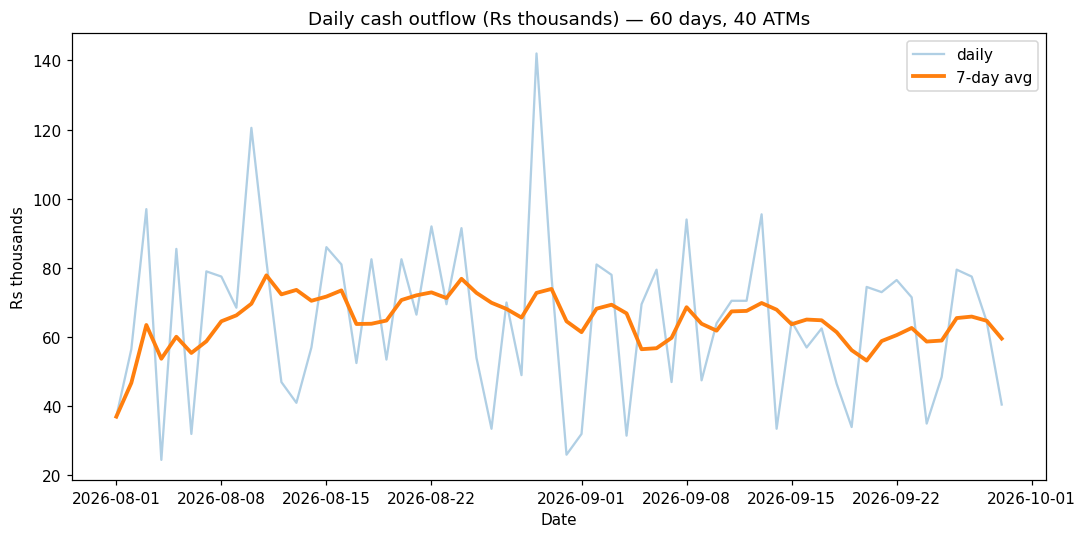

## Q2. When during the day do withdrawals peak?
Cash loaded at 6am is gone by evening — the hourly pattern tells us *when* ATMs run dry.

In [ ]:
wd = df.query("txn_type == 'CASH_WITHDRAWAL' and status == 'SUCCESS'").copy()
wd["hour"] = wd["txn_time"].str.slice(0, 2).astype(int)
hourly = wd.groupby("hour").size()
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hourly.index, hourly.values)
ax.set_title("Withdrawals by hour of day"); ax.set_xlabel("Hour")
ax.set_ylabel("Successful withdrawals"); ax.set_xticks(range(0, 24, 2));

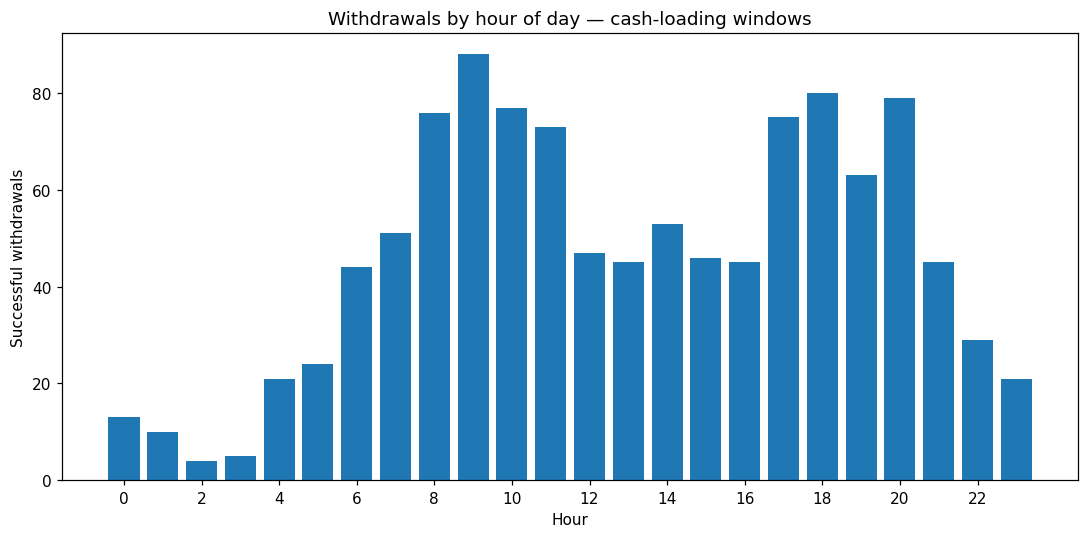

## Q3. Which region has the worst failure rate?
Failures = failed + timeout transactions. A regional skew points to network or maintenance issues, not user error.

In [ ]:
fail = (df.assign(is_fail=(df["status"] != "SUCCESS").astype(int))
              .groupby("region").agg(txns=("is_fail", "size"), fail_pct=("is_fail", "mean")))
fail["fail_pct"] *= 100
fail.sort_values("fail_pct", ascending=False).round(1)

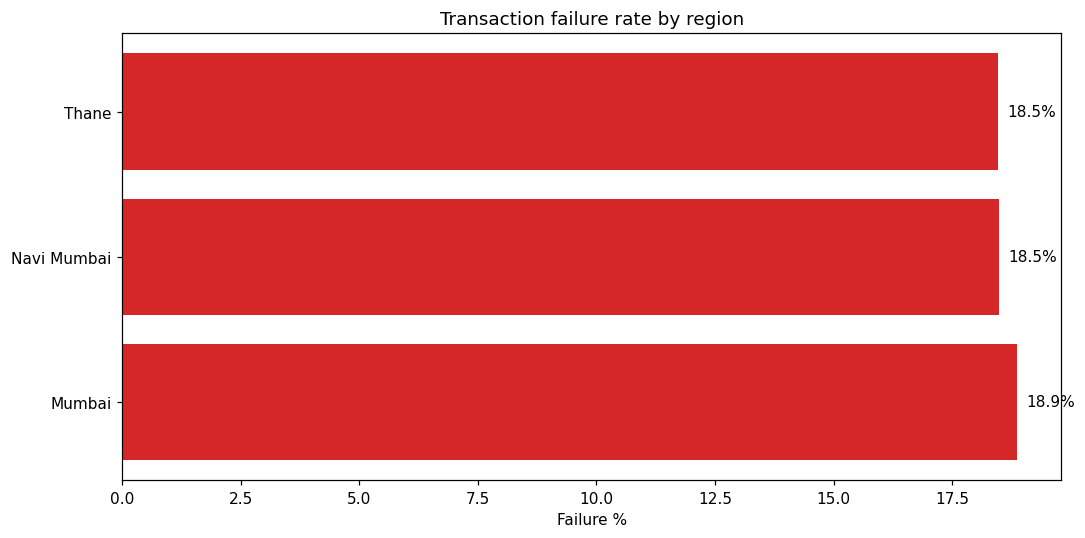

## Q4. Which ATMs should maintenance visit first?
Ranked by failure rate (minimum 20 transactions so a quiet ATM can't top the list on 2 bad txns).

In [ ]:
atm = (df.assign(is_fail=(df["status"] != "SUCCESS").astype(int))
             .groupby("atm_id").agg(txns=("is_fail", "size"), fail_pct=("is_fail", "mean")))
atm["fail_pct"] *= 100
worst = atm[atm["txns"] >= 20].sort_values("fail_pct", ascending=False).head(10)
worst.round(1)

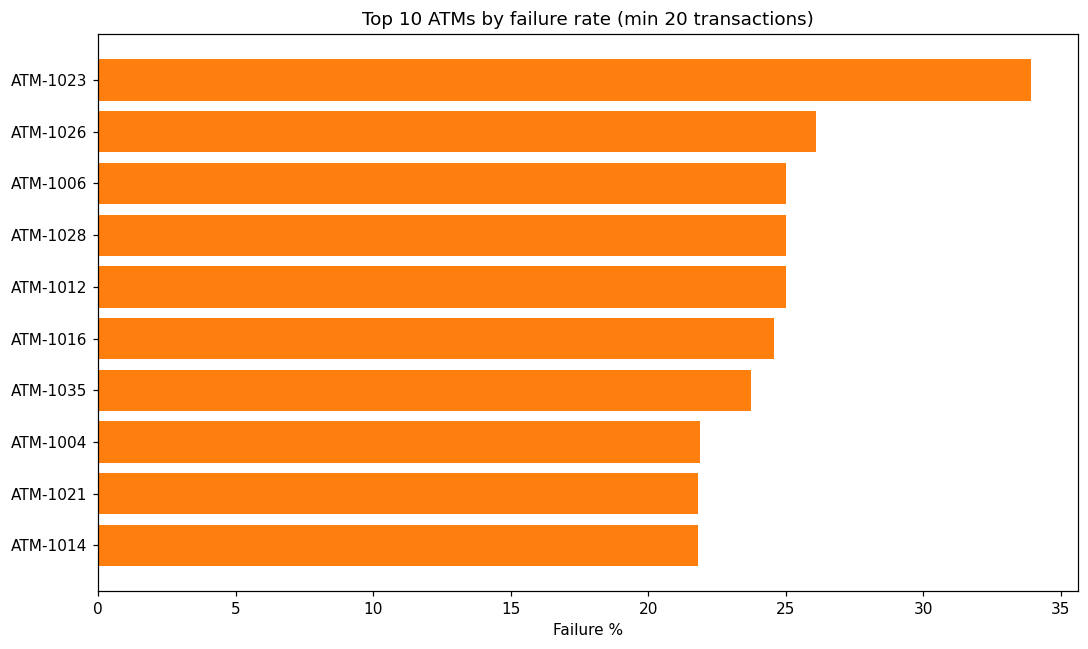

## Q5. What does a typical withdrawal look like?
The amount distribution sets the denomination mix for cash loading.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df.query("txn_type == 'CASH_WITHDRAWAL' and status == 'SUCCESS'")["amount"].dropna(),
        bins=[0, 500, 1000, 2000, 5000, 10000, 20000], edgecolor="white")
ax.set_title("Withdrawal amount distribution")
ax.set_xlabel("Amount (Rs)"); ax.set_ylabel("Count");

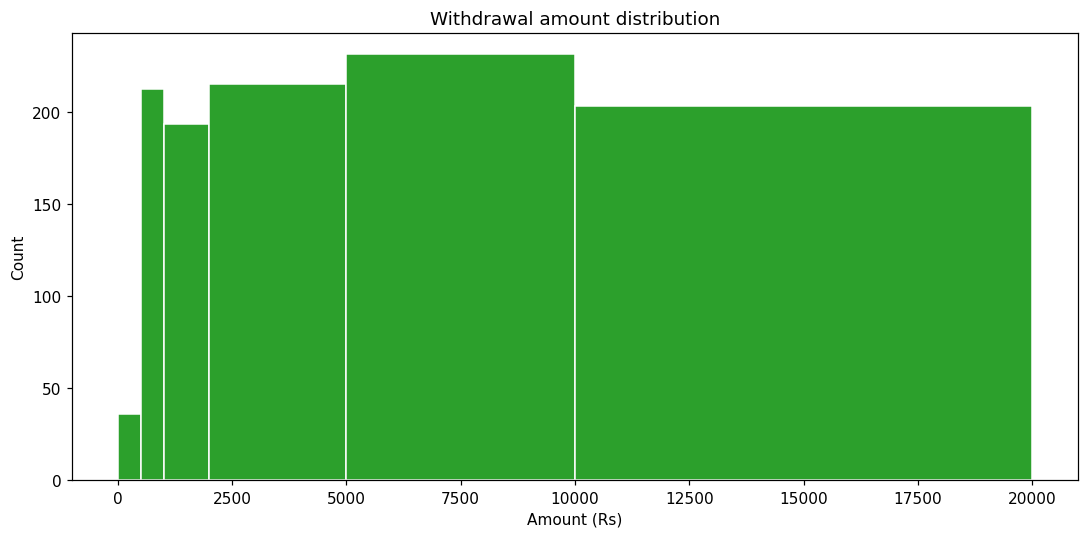

## Findings & recommendations
- **Demand peaks at 9am and 6–8pm** — schedule cash loading before 8am so machines survive the evening rush.
- **Weekend volumes run higher** — raise loading limits Fri–Sun.
- **~19% transaction failure rate, worst in Mumbai region** — the top-10 ATM list above is the maintenance visit order; error-code E21 dominates and deserves a root-cause check.
- **Median withdrawal is Rs 2,000** — stock Rs 500/2000 notes heaviest.

*Next step: join this with actual cash-loading logs to measure stockout rate directly.*